In [1]:
import os
from typing import Optional

from dotenv import load_dotenv
from langchain_core.utils.utils import secret_from_env
from langchain_openai import ChatOpenAI
from pydantic import Field, SecretStr

load_dotenv()

class ChatOpenRouter(ChatOpenAI):
    openai_api_key: Optional[SecretStr] = Field(
        alias="api_key", default_factory=secret_from_env("OPENROUTER_API_KEY", default=None)
    )
    @property
    def lc_secrets(self) -> dict[str, str]:
        return {"openai_api_key": "OPENROUTER_API_KEY"}

    def __init__(self,
                 openai_api_key: Optional[str] = None,
                 **kwargs):
        openai_api_key = openai_api_key or os.environ.get("OPENROUTER_API_KEY")
        super().__init__(base_url="https://openrouter.ai/api/v1", openai_api_key=openai_api_key, **kwargs)


model = ChatOpenRouter(model_name="google/gemini-2.5-flash", temperature=0.0)

/home/chen/proj/db_form_agent_system/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [1]:
import pandas as pd
df = pd.read_csv('/data/chen/data/hmdb/metabolites_endo_exo.csv')

In [3]:
df.head(10)

,Name,Origin
0,Glucose,Endogenous
1,Lactate,Endogenous
2,Pyruvate,Endogenous
3,Citrate,Endogenous
4,Isocitrate,Endogenous
5,?-Ketoglutarate,Endogenous
6,Succinate,Endogenous
7,Fumarate,Endogenous
8,Malate,Endogenous
9,Oxaloacetate,Endogenous


In [3]:
# use model to take input compound name and return if it is endogenous metabolite from human
def is_endogenous_compound(compound_name: str) -> str:
    prompt = f"Is the compound '{compound_name}' an endogenous metabolite from human? Answer 'Endogenous', 'Exogenous', 'Unclear'."
    response = model.predict(prompt)
    return response.strip()

In [4]:
df['Endogenous_LLM'] = df['Name'].apply(is_endogenous_compound)
df[['Name', 'Origin', 'Endogenous_LLM']]

/tmp/ipykernel_2549012/3245632064.py:4: LangChainDeprecationWarning: The method `BaseChatModel.predict` was deprecated in langchain-core 0.1.7 and will be removed in 1.0. Use :meth:`~invoke` instead.
  response = model.predict(prompt)


,Name,Origin,Endogenous_LLM
0,Glucose,Endogenous,Endogenous
1,Lactate,Endogenous,Endogenous
2,Pyruvate,Endogenous,Endogenous
3,Citrate,Endogenous,Endogenous
4,Isocitrate,Endogenous,Endogenous
...,...,...,...
95,Piperine,Exogenous,Exogenous
96,Glyphosate,Exogenous,Exogenous
97,DEET,Exogenous,Exogenous
98,PFOA,Exogenous,Exogenous


In [5]:
# calculate accuracy, precision, recall and F1 score
df = df[df['Endogenous_LLM']!='Unclear']
df['Endogenous_bool'] = df['Origin'] == 'Endogenous'
df['Endogenous_LLM_bool'] = df['Endogenous_LLM'] == 'Endogenous'

accuracy = (df['Endogenous_bool'] == df['Endogenous_LLM_bool']).mean()
precision = (df['Endogenous_bool'] & df['Endogenous_LLM_bool']).sum() / df['Endogenous_LLM_bool'].sum()
recall = (df['Endogenous_bool'] & df['Endogenous_LLM_bool']).sum() / df['Endogenous_bool'].sum()
f1 = 2 * (precision * recall) / (precision + recall)

accuracy, precision, recall, f1

(0.9887640449438202, 0.9803921568627451, 1.0, 0.99009900990099)

<Axes: >

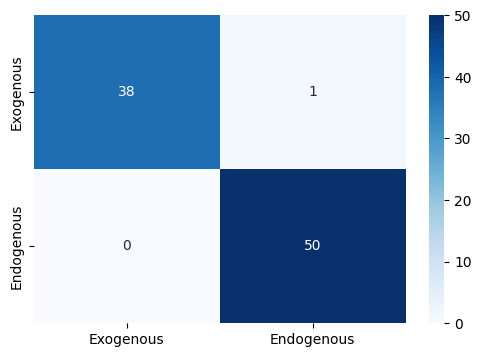

In [6]:
# plot the confusion matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(df['Endogenous_bool'], df['Endogenous_LLM_bool'])
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Exogenous', 'Endogenous'], yticklabels=['Exogenous', 'Endogenous'])

In [7]:
df.to_csv('metabolites_endo_exo_llm_gemini2.5.csv', index=False)

In [17]:
import pandas as pd

df = pd.read_csv("/data/chen/data/hmdb/metabolites.csv")

In [ ]:

# get 100 rows with 80% endogenous
df_endogenous = df[df['Endogenous']=='Yes'].sample(n=45, random_state=42)
df_non_endogenous = df[df['Endogenous']=='No'].sample(n=5, random_state=42)
df_sampled = pd.concat([df_endogenous, df_non_endogenous]).reset_index(drop=True)


In [20]:

df_sampled['Endogenous_LLM'] = df_sampled['Name'].apply(is_endogenous_compound)
df_sampled[['Name', 'Endogenous', 'Endogenous_LLM']]

,Name,Endogenous,Endogenous_LLM
0,TG(i-16:0/a-17:0/18:0)[rac],Yes,Unclear
1,TG(i-22:0/i-18:0/a-25:0)[rac],Yes,Unclear
2,Alanylarginine,Yes,Unclear
3,"CL(18:1(9Z)/16:0/22:5(4Z,7Z,10Z,13Z,16Z)/18:1(...",Yes,Unclear
4,TG(12:0/i-20:0/14:0),Yes,Unclear
5,TG(i-17:0/i-16:0/i-15:0),Yes,Unclear
6,TG(18:0/a-21:0/i-19:0)[rac],Yes,Unclear
7,"CL(i-12:0/14:0/18:2(9Z,11Z)/18:2(9Z,11Z))",Yes,Unclear
8,S-4'-Hydroxywarfarin,Yes,Unclear
9,"PC(18:0/22:5(4Z,7Z,10Z,13Z,16Z))",Yes,Endogenous


In [21]:
# unclear ratio
unclear_ratio = (df_sampled['Endogenous_LLM']=='Unclear').mean()
unclear_ratio

0.88

In [13]:
# calculate accuracy, precision, recall and F1 score
df_sampled = df_sampled[df_sampled['Endogenous_LLM']!='Unclear']
df_sampled['Endogenous_bool'] = df_sampled['Endogenous'] == 'Yes'
df_sampled['Endogenous_LLM_bool'] = df_sampled['Endogenous_LLM'] == 'Endogenous'

accuracy = (df_sampled['Endogenous_bool'] == df_sampled['Endogenous_LLM_bool']).mean()
precision = (df_sampled['Endogenous_bool'] & df_sampled['Endogenous_LLM_bool']).sum() / df_sampled['Endogenous_LLM_bool'].sum()
recall = (df_sampled['Endogenous_bool'] & df_sampled['Endogenous_LLM_bool']).sum() / df_sampled['Endogenous_bool'].sum()
f1 = 2 * (precision * recall) / (precision + recall)

accuracy, precision, recall, f1

/tmp/ipykernel_2549012/1808926640.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_sampled['Endogenous_bool'] = df_sampled['Endogenous'] == 'Yes'
/tmp/ipykernel_2549012/1808926640.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_sampled['Endogenous_LLM_bool'] = df_sampled['Endogenous_LLM'] == 'Endogenous'


(0.8333333333333334, 0.5, 1.0, 0.6666666666666666)

<Axes: >

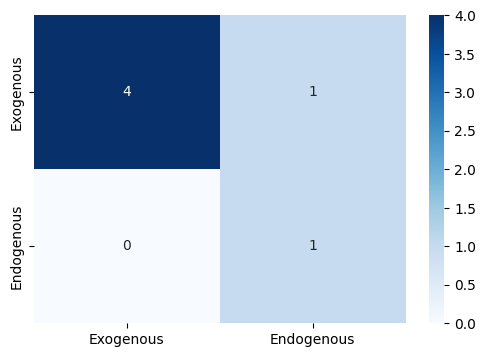

In [14]:
# plot the confusion matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(df_sampled['Endogenous_bool'], df_sampled['Endogenous_LLM_bool'])
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Exogenous', 'Endogenous'], yticklabels=['Exogenous', 'Endogenous'])

In [ ]:
df_sampled.to_csv("data/metabolites_llm_labled.csv", index=False)

In [28]:
df_temp = df_sampled[['Name', 'Endogenous', 'Endogenous_LLM']][df_sampled['Endogenous_LLM'] != 'Unclear']
df_temp['Endogenous'] = df_temp['Endogenous'].map({'Yes': 'Endogenous', 'No': 'Exogenous'})
df_temp = df_temp.rename(columns={'Endogenous': 'Ground Truth', 'Endogenous_LLM': 'LLM Prediction'})
df_temp

,Name,Ground Truth,LLM Prediction
9,"PC(18:0/22:5(4Z,7Z,10Z,13Z,16Z))",Endogenous,Endogenous
45,alpha-Linolenic acid,Exogenous,Endogenous
46,Rhodamine B,Exogenous,Exogenous
47,Gallium,Exogenous,Exogenous
48,Potassium,Exogenous,Exogenous
49,Erythrosine,Exogenous,Exogenous
